In [1]:
import os
import sys
from pathlib import Path
from datetime import datetime, timedelta, timezone


from Legacy.Binance_new import Binance # Get_Price_Data_By_Time

In [2]:
bn = Binance.instantiate(connect=False)

Initializing Binance singleton...


In [3]:
# Get_Price_Data_By_Time function seamlessly collects/creates price candles from Binance.
datatype = "klines" # "aggTrades" #, "klines"
symbol = "BTCUSDT"      # Any pair listed on Binance.

# dates that worked
# start = datetime(2018, 1, 1)    # Any datetime. Note Binance started operation in July 2017.
# end = datetime(2026, 3, 26) # + timedelta(minutes=100)     # Any datetime

start = datetime(2020, 1, 1)    # Any datetime. Note Binance started operation in July 2017.
end = datetime(2025, 2, 26) # + timedelta(minutes=100)     # Any datetime

interval = '1m'    # in '1m', '3m', '5m', '15m', '30m', '1h', '2h', '4h', '6h', '8h', '12h', '1d'.  (excludes: '3d', '1w')
print(f"interval: {interval}")
#------------------------------------------------------------------------------------------------------------------
candles, nFills, successful, _, reason = bn.Get_Price_Data_By_Time(datatype, symbol, interval, start, end)
print(reason)
if successful:          # price is a numpy array.
    print("\n Successful !!!!!!!!!! (nCandles, nAttributes) = {}, nCreated = {}".format(candles.shape, nFills))

interval: 1m
nCreated/nTotal/expected 2325/2711520/2711520. 
Returning 10 columns: O H L C V, Quote V, nTrades, Buy base V, Buy quote V, Mark (0: original not forged)


 Successful !!!!!!!!!! (nCandles, nAttributes) = (2711520, 10), nCreated = 2325


In [4]:
opens = candles[:, 0]
highs = candles[:, 1]
lows = candles[:, 2]
closes = candles[:, 3]
volumes = candles[:, 4]

In [5]:
import matplotlib.pyplot as plt
import numpy as np

def plot_array1(arr, title="Price History", xlabel="Time", ylabel="Price", figsize=(18, 3), flip=False, save_path=None, vlines=None, recolors=None):
    """
    Plot a 1D numpy array
    
    Parameters:
    - arr: numpy array of shape (n,)
    - title: str - plot title
    - xlabel: str - x-axis label
    - ylabel: str - y-axis label
    - figsize: tuple - figure size (width, height)
    - flip: bool - if True, reverse the x-axis (plot from right to left)
    - save_path: str - if provided, saves plot to this path
    """
    if arr is None or len(arr) == 0:
        print("❌ No data to plot")
        return
    
    plt.figure(figsize=figsize)
    if vlines:
        plt.axvline(x=vlines, color='yellow', linewidth=0.5, alpha=0.7)
        # y_min, y_max = plt.ylim()  # Get current y-axis limits
        # plt.vlines(x=vlines, ymin=y_min, ymax=y_max, colors='red', linewidth=0.5, alpha=0.7)
    plt.plot(arr, linewidth=1, color='blue')
    if recolors:
        plt.plot(arr[:recolors], linewidth=1, color='red')
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid(True, alpha=0.3)
    
    if flip:
        plt.gca().invert_xaxis()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"✅ Plot saved to {save_path}")
    else:
        plt.show()
        
def plot_array(arr, title="Price History", xlabel="Time", ylabel="Price", figsize=(18, 3), flip=False, save_path=None, vlines=None, recolors=None, show_stats=True):
    """
    Plot a 1D numpy array
    
    Parameters:
    - arr: numpy array of shape (n,)
    - title: str - plot title
    - xlabel: str - x-axis label
    - ylabel: str - y-axis label
    - figsize: tuple - figure size (width, height)
    - flip: bool - if True, reverse the x-axis (plot from right to left)
    - save_path: str - if provided, saves plot to this path
    - vlines: int or list - x-coordinate(s) for vertical line(s)
    - recolors: int - index to recolor the plot from that point
    - show_stats: bool - if True, display mean and std as text annotation
    """
    if arr is None or len(arr) == 0:
        print("❌ No data to plot")
        return
    
    plt.figure(figsize=figsize)
    
    # Plot main line
    plt.plot(arr, linewidth=1, color='blue', label='Value')
    
    # Handle recolor if specified
    if recolors:
        plt.plot(arr[:recolors], linewidth=1, color='red') # , label='Recolored section')
    
    # Handle vertical lines
    if vlines is not None:
        if isinstance(vlines, (int, float)):
            vlines = [vlines]
        for vline in vlines:
            plt.axvline(x=vline, color='yellow', linewidth=0.5, alpha=0.7)
    
    # Calculate statistics
    if show_stats:
        mean_val = np.mean(arr)
        std_val = np.std(arr)
        min_val = np.min(arr)
        max_val = np.max(arr)
        
        # Create statistics text
        stats_text = f'μ: {mean_val:.5f} ± {std_val:.5f}\nMin: {min_val:.5f}, Max: {max_val:.5f}'
        
        # Add text annotation in the top right corner
        plt.text(0.95, 0.95, stats_text,
                transform=plt.gca().transAxes,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
        
        # Optionally add horizontal line for mean
        plt.axhline(y=mean_val, color='red', linestyle='--', linewidth=1, alpha=0.5, label=f'Mean: {mean_val:.5f}')
        
        # Add std deviation bands
        plt.axhspan(mean_val - std_val, mean_val + std_val, alpha=0.2, color='gray', label=f'±1σ [{mean_val-std_val:.5f}, {mean_val+std_val:.5f}]')
    
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid(True, alpha=0.3)
    plt.legend(loc='upper left')
    
    if flip:
        plt.gca().invert_xaxis()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"✅ Plot saved to {save_path}")
        plt.close()
    else:
        plt.show()


def plot_arrays(arrays, labels=None, title="Price History", xlabel="Time", ylabel="Price", figsize=(18, 1), flip=False, save_path=None):
    """
    Plot multiple 1D numpy arrays on the same graph
    
    Parameters:
    - arrays: list of numpy arrays, each of shape (n,)
    - labels: list of str - labels for each array
    - title: str - plot title
    - xlabel: str - x-axis label
    - ylabel: str - y-axis label
    - figsize: tuple - figure size (width, height)
    - flip: bool - if True, reverse the x-axis (plot from right to left)
    - save_path: str - if provided, saves plot to this path
    """
    if not arrays:
        print("❌ No data to plot")
        return
    
    plt.figure(figsize=figsize)
    
    colors = ['blue', 'red', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan']
    
    for i, arr in enumerate(arrays):
        if arr is None or len(arr) == 0:
            continue
        
        color = colors[i % len(colors)]
        label = labels[i] if labels and i < len(labels) else f"Series {i+1}"
        plt.plot(arr, linewidth=1, color=color, label=label)
    
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid(True, alpha=0.3)
    plt.legend()
    
    if flip:
        plt.gca().invert_xaxis()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"✅ Plot saved to {save_path}")
    else:
        plt.show()

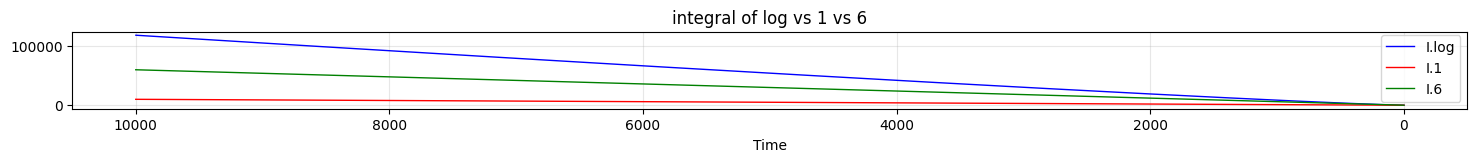

[-1.4426950408889634, -0.8853900817779269, 0.4268023794965784, 2.229219836444146, 4.396165269991995, 6.853604758993158, 9.552619168180485, 12.458439672888291, 15.545069644980142, 18.792330539983997, 22.184102355231673, 25.707209517986318, 29.350680804277676, 33.10523833636096, 36.962933320793326, 40.916879345776586, 44.9610526061434, 49.090139289960284, 53.29941697853781, 57.58466107996797, 61.94207001968574, 66.36820471046336, 70.85993904886513, 75.41441903597264, 80.02902872214403, 84.70136160855536, 89.42919645441165, 94.21047667272195, 99.04329267291966, 103.92586664158665]
[(59217.721525660796, -1.164042561333445), (-1.164042561333445, -0.22929385114067424), (-0.22929385114067424, 1.3280111079703623), (1.3280111079703623, 3.3126925532180707), (3.3126925532180707, 5.624885014492577), (5.624885014492577, 8.20311196358682), (8.20311196358682, 11.005529420534387), (11.005529420534387, 14.001754658934217), (14.001754658934217, 17.16870009248207), (17.16870009248207, 20.488216447607833)

In [6]:
import math

nNodes = 10000

i_log = [ ((k) * math.log(k) - k) / math.log(2) for k in range(1, nNodes) ]  # integral of log
i_1 = [k for k in range(nNodes)]   # integral of 1
i_6 = [6 * k for k in range(nNodes)]
plot_arrays([i_log, i_1, i_6], 
            labels=["I.log", "I.1", "I.6"], 
            title="integral of log vs 1 vs 6", 
            ylabel="", flip=True)

nodes = i_log
nodes = [x for x in nodes]

# plot_array(nodes, title="BTCUSDT Middle Price", ylabel="", flip=True)
print(nodes[:30])

N = 15
intervals = [((nodes[i-1]+nodes[i])/2, (nodes[i]+nodes[i+1])/2) for i in range(N-1)]
print(intervals)

In [ ]:
def extract(array, intervals, bidir=False): # bidir = False is better.
    ext = []
    for (a, b) in intervals:
        assert a < b
        if a < 0 and b < 0: continue
        if a < 0: a = -0.99999
        assert a < b
        
        if math.ceil(b) >= array.shape[0]: break
        
        s = 0
        assert math.floor(a) == math.ceil(a) - 1
        
        s = s + array[math.ceil(a)] * (math.ceil(a)-a)      # Lose (a - math.floor(a)) part of array[math.ceil(a)]
        s = s + array[math.ceil(b)] * (b-math.floor(b))     # Gain (b - math.floor(a)) part of array[math.ceil(b)]

        for i in range(math.ceil(a) + 1, math.floor(b)+1):
            s += array[i]
            
        if bidir:
            s = s + array[math.floor(a)] * (math.ceil(a)-a)      # Lose (a - math.floor(a)) part of array[math.floor(a)]
            s = s + array[math.floor(b)] * (b-math.floor(b))     # Gain (b - math.floor(a)) part of array[math.floor(b)]

            for i in range(math.ceil(a), math.floor(b)):
                s += array[i]
                
        if bidir:
            s /= 2
                           
        ext.append(s/(b-a))
        
    return np.array(ext)
        

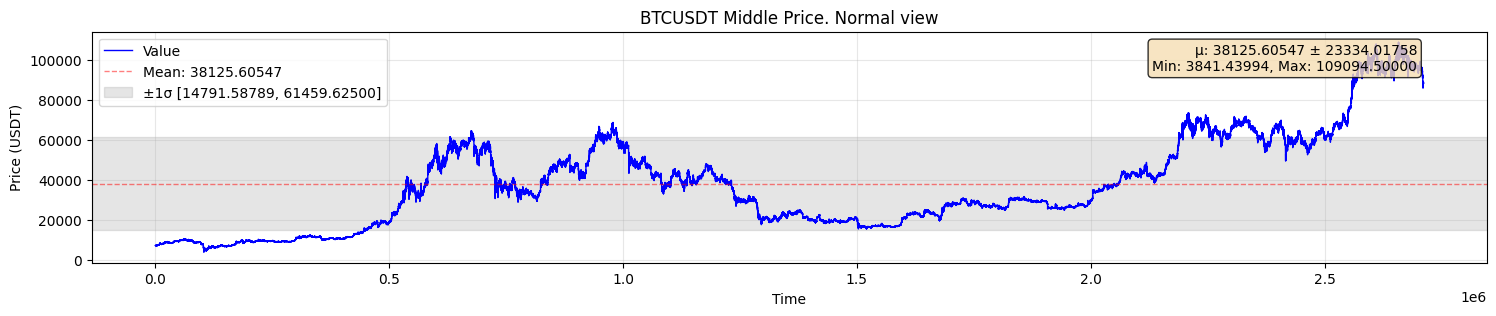

mid (9999,), vol (9999,)


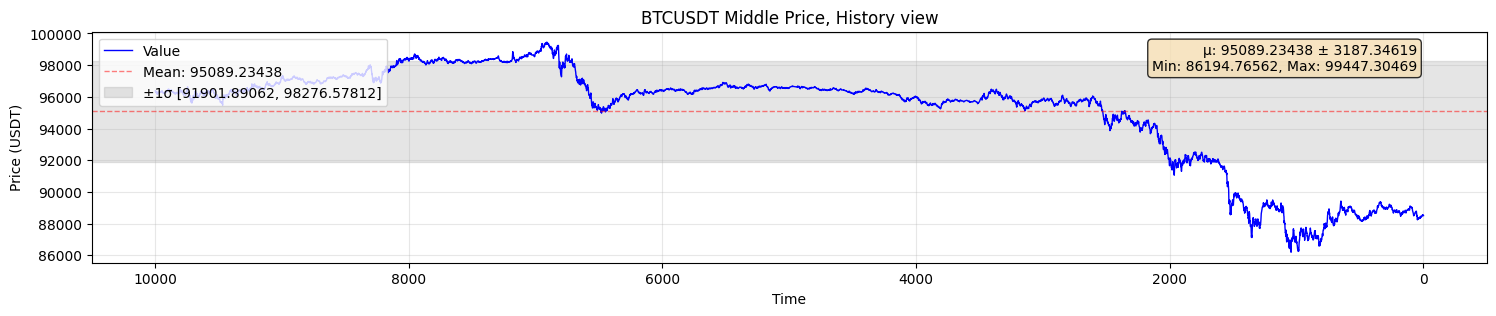

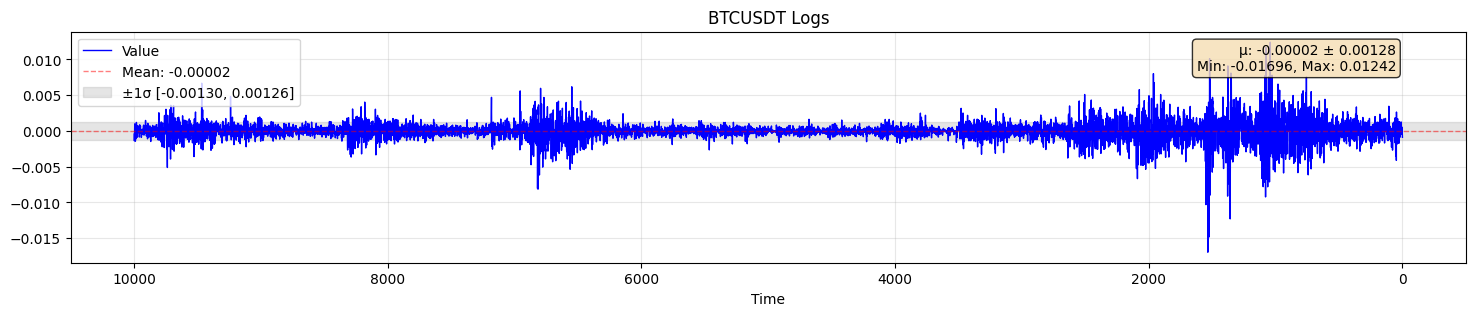

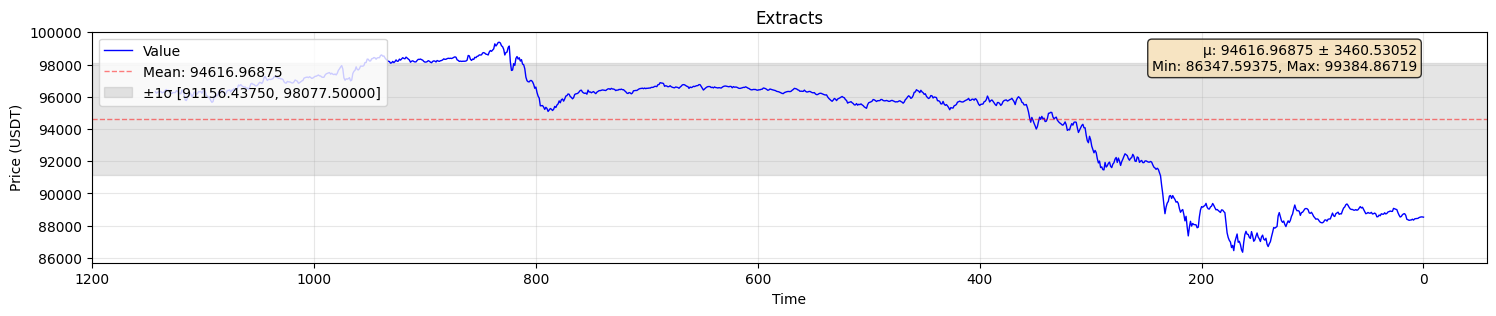

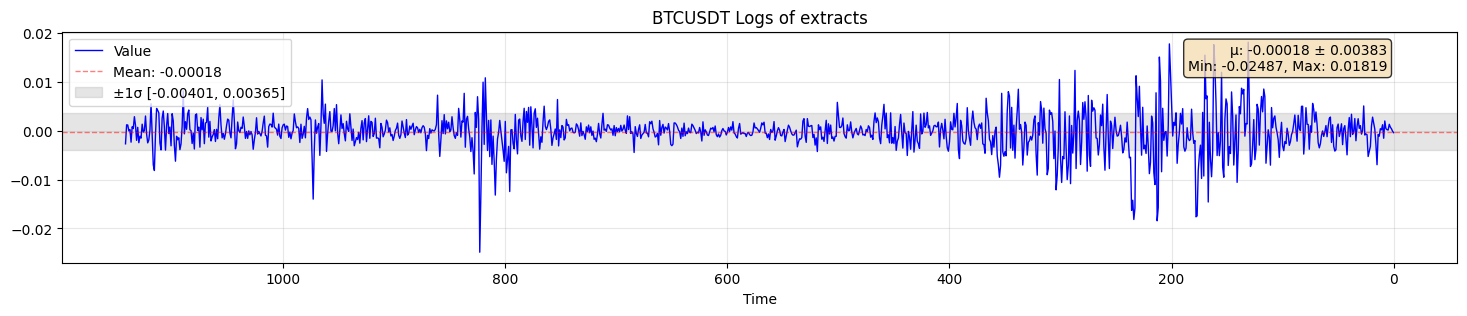

In [8]:

middles = (highs + lows) / 2

plot_array(middles, title="BTCUSDT Middle Price. Normal view", ylabel="Price (USDT)", flip=False)


mid = middles[::-1] [:nNodes-1]
vol = volumes[::-1] [:nNodes-1]
print(f"mid {mid.shape}, vol {vol.shape}")

# Plot single array
vlines = [math.floor(c) for c in nodes if c >= 0][:mid.shape[0]]
plot_array(mid, title="BTCUSDT Middle Price, History view", ylabel="Price (USDT)", flip=True) #, vlines=vlines)

base = 1.5

logs = np.log(mid[:-1]/mid[1:]) / np.log(base)
plot_array(logs, title="BTCUSDT Logs", ylabel="", flip=True)

N = mid.shape[0]
intervals = [((nodes[i-1]+nodes[i])/2, (nodes[i]+nodes[i+1])/2) for i in range(1, N-1)]

ext = extract(mid, intervals, bidir=False)
plot_array(ext, title="Extracts", ylabel="Price (USDT)", flip=True)

logs = np.log(ext[:-1] / ext[1:]) / np.log(base)
plot_array(logs, title="BTCUSDT Logs of extracts", ylabel="", flip=True)
    

In [9]:
def plot_xy(array, title="", pred=5, base=1.5, bidir=False):
    whole_ext = extract(array, intervals, bidir=bidir)
    future_logs = np.log(whole_ext[:-1] / whole_ext[1:]) / np.log(base)
    plot_array(future_logs, title=title + ", extracted as a whole", ylabel="", flip=True)

    offset = 3
    past_ext = extract(array[pred:], intervals, bidir=bidir)
    xy_logs = np.concat([future_logs[:pred], (np.log(past_ext[:-1] / past_ext[1:])[offset:]) / np.log(base)])
    plot_array(xy_logs, title=title + ", extracted as x and y(red)", ylabel="", flip=True, recolors=pred)
    
    print(f"x_len: {(np.log(past_ext[:-1] / past_ext[1:])[offset:]).shape[0]}, y_len: {pred}")

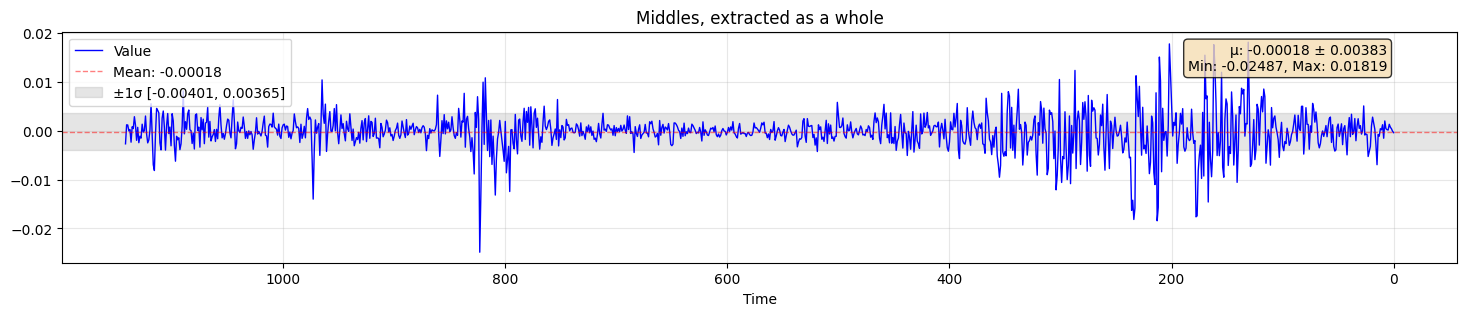

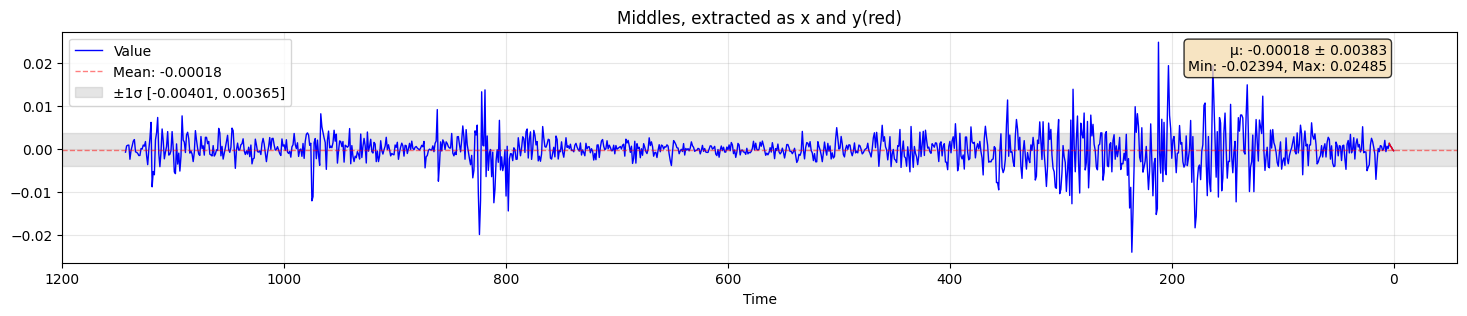

x_len: 1139, y_len: 5


In [10]:
plot_xy(mid, title="Middles", bidir=False)


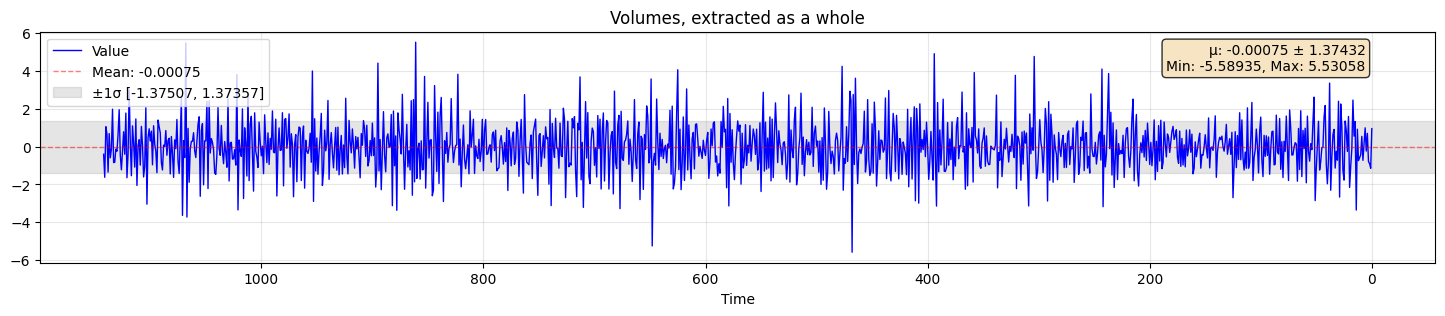

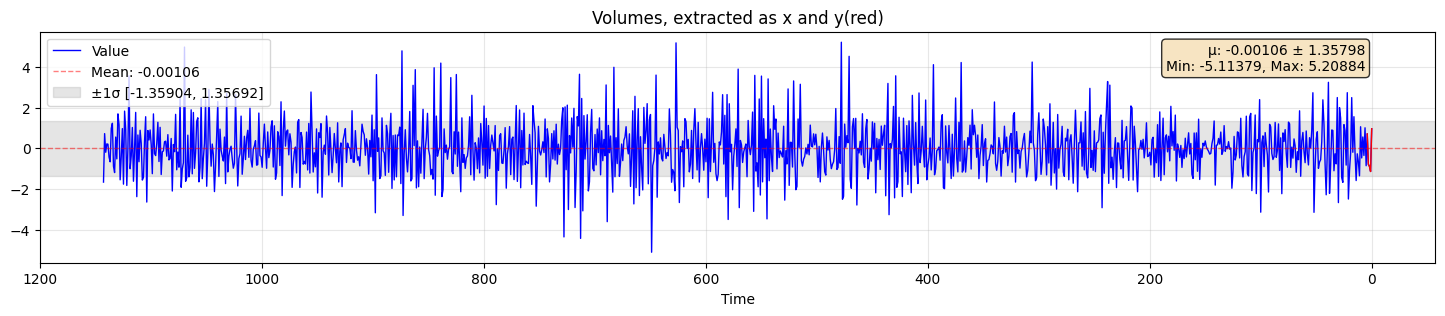

x_len: 1139, y_len: 5


In [11]:
plot_xy(vol, title="Volumes", bidir=False)


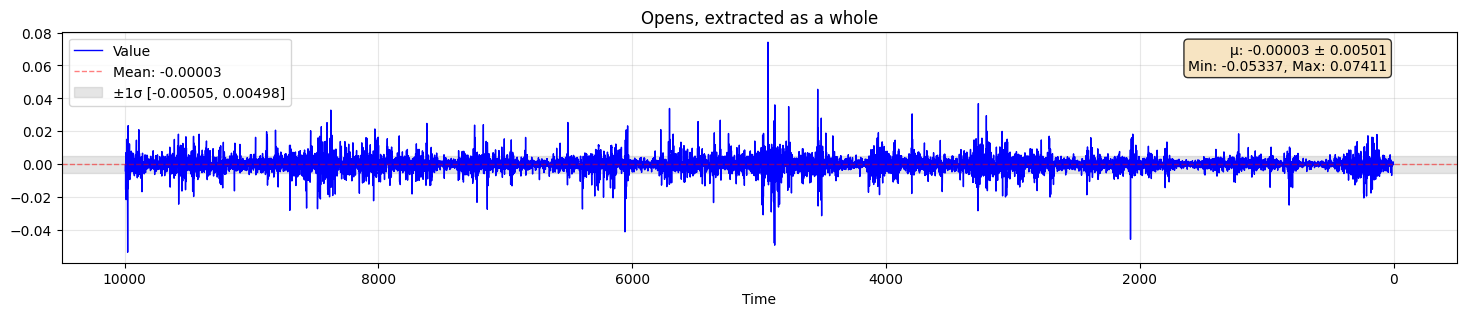

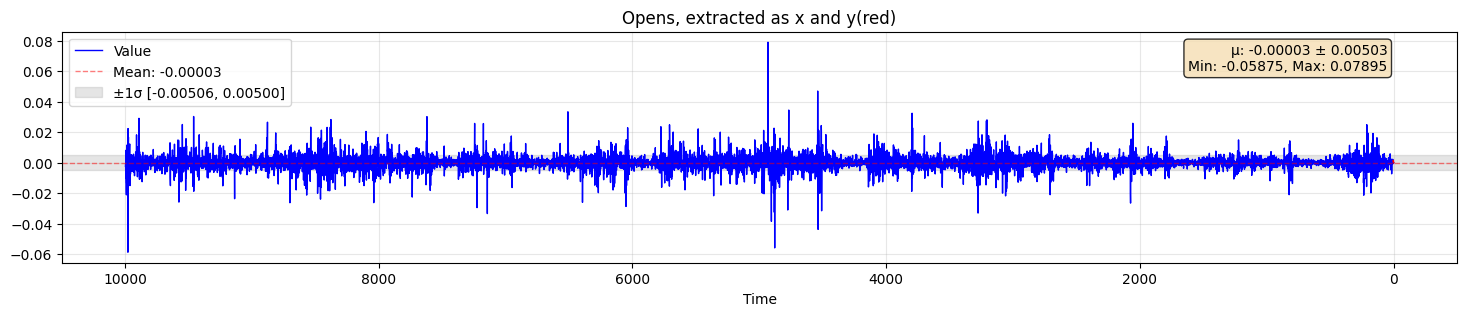

x_len: 9992, y_len: 5


In [12]:
plot_xy(opens[::-1], title="Opens", bidir=False)

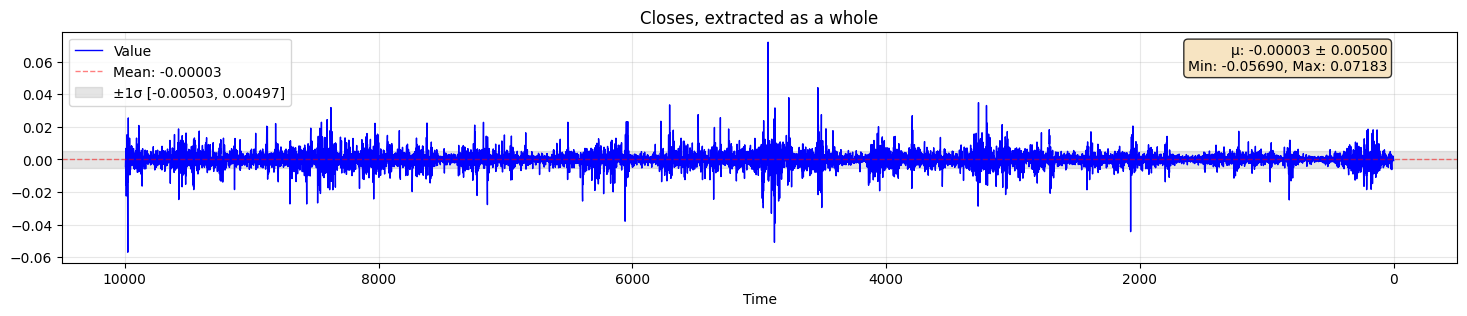

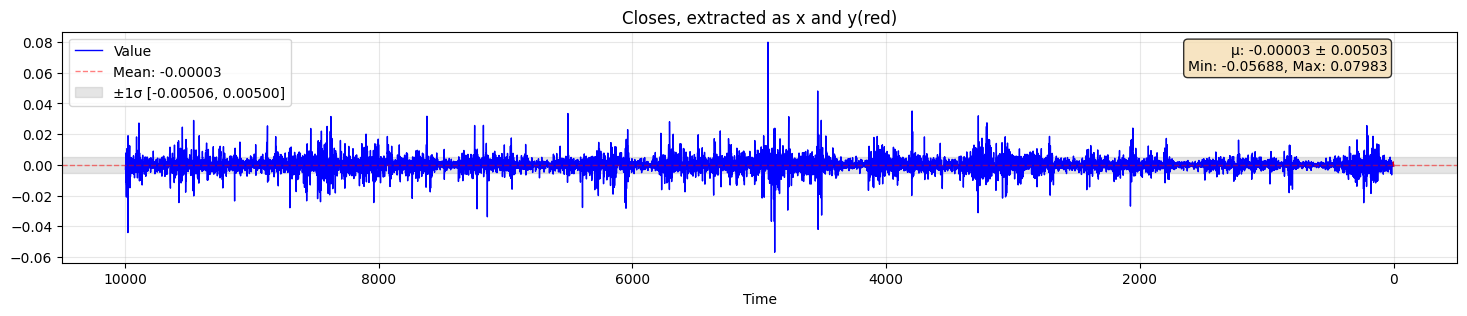

x_len: 9992, y_len: 5


In [13]:
plot_xy(closes[::-1], title="Closes", bidir=False)